# SEM.9.10 — Notebook 1: A dynamic rating with a Kalman filter

Reproducibility notebook for **SFFS technical report SEM.9.10, *The Dynamic Rating at Bweramule: a Stage–Discharge Relation that Moves with the River*** (Ministry of Water and Environment, Uganda, 2026), Sections 4 and 5.

A fixed rating curve is exact on the day of its last gauging and silently wrong after it if the river bed or banks move. The dynamic rating keeps the installed curve and adds a **stage shift that drifts with time as a random walk**, estimated from all gaugings by a **Kalman filter** (and a Rauch–Tung–Striebel smoother for the history). Its 90 % band widens every day without a gauging and narrows again at the next one.

$$Q(h,t) = Q_{base}\big(h-\delta(t)\big),\qquad \delta(t_i)=\delta(t_{i-1})+w_i,\; w_i\sim N\big(0,\,q\,\Delta t\big),$$
$$h_i - h_{base}(Q_i) = \delta(t_i) + e_i,\qquad e_i \sim N\big(0,\,(\sigma_Q\,\partial h/\partial\ln Q)^2\big).$$

The drift rate $q$ and the gauging error $\sigma_Q$ are estimated by maximum likelihood; a fixed rating is the special case $q=0$, so the two can be compared by likelihood and AIC.

**Data note.** The 191 gaugings at Bweramule (DWRM station 85205, 1950–2025) used in the report are held by the Ministry of Water and Environment, Uganda, and are **not distributed** with this package; they can be requested from the Ministry. The notebook runs on a **synthetic example** generated below, with a drift rate and gauging error close to those found in the report (6.8 cm/√yr, 4.2 %), so that the method can be checked. To use real data, set `GAUGINGS` to a CSV with columns `date` (YYYY-MM-DD), `stage_m`, `Q_m3s`, `era` (`historic` or `modern`), and give the base rating(s).

In [1]:
import os, sys, math, csv, datetime as dt
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath("."))
import semliki_dynrating as D
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
GAUGINGS = None                     # path to a real gaugings CSV; None = synthetic example
BASE = (9.0, 8.0, 2.5)              # base rating Q = a (h - h0)^c used for the historic record (illustrative values)
rng = np.random.default_rng(42)

## 1  The gaugings (synthetic example unless `GAUGINGS` is set)

In [2]:
q_of_h, h_of_q, dh_dlnq = D.power_rating(*BASE)
if GAUGINGS:
    G = [dict(date=dt.date.fromisoformat(r["date"][:10]), h=float(r["stage_m"]), Q=float(r["Q_m3s"]), era=r["era"])
         for r in csv.DictReader(open(GAUGINGS))]
else:
    # ILLUSTRATIVE ONLY - not Semliki data: 176 'historic' gaugings 1950-75 and 11 'modern' ones 2024-25
    TRUE_Q, TRUE_SIG = 0.068 ** 2, 0.042
    G, shift, last = [], -0.17, dt.date(1950, 1, 1)
    dates = sorted(dt.date(1950, 1, 1) + dt.timedelta(days=int(x)) for x in rng.uniform(0, 25.6 * 365.25, 176))
    dates += sorted(dt.date(2024, 3, 1) + dt.timedelta(days=int(x)) for x in rng.uniform(0, 570, 11))
    for d in dates:
        shift += rng.normal(0, math.sqrt(TRUE_Q * (d - last).days / 365.25)); last = d
        Q = float(rng.uniform(50, 320)); h = float(h_of_q(Q)) + shift
        G.append(dict(date=d, h=h, Q=Q * math.exp(rng.normal(0, TRUE_SIG)), era="historic" if d.year < 2000 else "modern", true_shift=shift))
H = [g for g in G if g["era"] == "historic"]; Mo = [g for g in G if g["era"] == "modern"]
print("%d historic gaugings %s - %s, %d modern %s - %s" % (len(H), H[0]["date"], H[-1]["date"], len(Mo), Mo[0]["date"], Mo[-1]["date"]))

176 historic gaugings 1950-03-10 - 1974-12-23, 11 modern 2024-08-28 - 2025-09-17


## 2  Estimate the drift rate on the historic record (report Section 4.2)

In [3]:
t = [(g["date"] - H[0]["date"]).days / D.YEAR for g in H]
F = D.fit_drift(t, [g["h"] for g in H], [g["Q"] for g in H], h_of_q, dh_dlnq)
if not GAUGINGS:
    print("(the synthetic record was generated with %.3f m/sqrt(yr) and %.1f %%)" % (math.sqrt(TRUE_Q), 100 * TRUE_SIG))

drift rate 0.055 m per sqrt(year); gauging error 4.5 %; loglik 231.0 (fixed rating 139.3); AIC -458 vs -277; one-step z sd 1.00, 93 % inside the 90 % band
(the synthetic record was generated with 0.068 m/sqrt(yr) and 4.2 %)


## 3  The control has moved: smoothed stage shift (report Section 5.1)

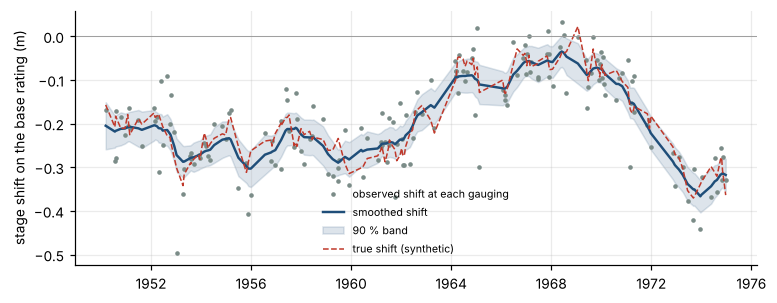

In [4]:
dd = [g["date"] for g in H]; xs = np.array(F["smoothed_shift"]); ss = np.array(F["smoothed_sd"])
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(dd, F["obs_shift"], ".", ms=4, color="#7B8C88", label="observed shift at each gauging")
ax.plot(dd, xs, color="#1F4E79", lw=1.6, label="smoothed shift")
ax.fill_between(dd, xs - D.Z90 * ss, xs + D.Z90 * ss, color="#1F4E79", alpha=.15, label="90 % band")
if not GAUGINGS:
    ax.plot(dd, [g["true_shift"] for g in H], "--", color="#C0392B", lw=1, label="true shift (synthetic)")
ax.axhline(0, color="#999", lw=.6); ax.set_ylabel("stage shift on the base rating (m)"); ax.legend(fontsize=7, frameon=False); ax.grid(alpha=.25)
plt.show()

## 4  Is a drifting rating better? (report Section 5.2)

Measured, not assumed: the gauging scatter, the likelihood and AIC of the fixed and the drifting rating, and the honesty of the one-step-ahead band (the share of gaugings that fall inside the 90 % band predicted before they were made).

In [5]:
print("fixed rating   : scatter %.1f %%, loglik %.1f, AIC %.0f" % (100 * F["sigma_static"], F["loglik_static"], F["aic_static"]))
print("drifting rating: scatter %.1f %%, loglik %.1f, AIC %.0f" % (100 * F["sigma_gauging"], F["loglik"], F["aic"]))
w = [D.Z90 * math.sqrt(r[3]) for r in F["filter"]][5:]
print("one-step 90 %% band on the next gauging: +-%.2f m on average; %.0f %% of gaugings inside it" % (np.mean(w), 100 * F["cover90"]))

fixed rating   : scatter 9.1 %, loglik 139.3, AIC -277
drifting rating: scatter 4.5 %, loglik 231.0, AIC -458
one-step 90 % band on the next gauging: +-0.11 m on average; 93 % of gaugings inside it


## 5  The modern shift and the rating today (report Sections 4.3 and 5.3)

The modern shift is estimated on the modern gaugings against the installed modern rating, starting from a wide prior (0.30 m), with the drift rate found above and a 3 % ADCP error. Between gaugings the mean is held and the variance grows by $q$ per year, so the band at an issue date depends on the days since the last gauging.

In [6]:
MODERN_BASE = BASE                    # the installed modern rating (illustrative: same form)
mq, mh, mk = D.power_rating(*MODERN_BASE)
bh = np.linspace(MODERN_BASE[1] + 0.05, MODERN_BASE[1] + 8, 400); bq = mq(bh)
SIGMA_ADCP, PRIOR_SD = 0.03, 0.30
tm = [(g["date"] - Mo[0]["date"]).days / D.YEAR for g in Mo]
dm = [g["h"] - float(mh(g["Q"])) for g in Mo]
sdm = [SIGMA_ADCP * float(mk(g["h"])) for g in Mo]
ll, rec = D.kalman(tm, dm, sdm, F["q_m2_per_yr"], 0.0, PRIOR_SD ** 2)
shift, sd_last = rec[-1][4], math.sqrt(rec[-1][5])
ISSUE = Mo[-1]["date"] + dt.timedelta(days=375)
age = (ISSUE - Mo[-1]["date"]).days
sd_now = math.sqrt(sd_last ** 2 + F["q_m2_per_yr"] * age / D.YEAR)
R = D.Rating(bh, bq, shift, sd_now)
print("issue %s, last gauging %s (%d days): shift %+.1f cm; 90 %% stage band +-%.2f m (+-%.2f m at the last gauging)"
      % (ISSUE, Mo[-1]["date"], age, 100 * shift, D.Z90 * sd_now, D.Z90 * sd_last))
for Q in (150, 200, 250, 300):
    h, lo, hi = R.stage(Q); print("   %3d m3/s -> stage %.2f m (90 %%: %.2f - %.2f)" % (Q, h, lo, hi))

issue 2026-09-27, last gauging 2025-09-17 (375 days): shift -46.9 cm; 90 % stage band +-0.10 m (+-0.04 m at the last gauging)
   150 m3/s -> stage 10.61 m (90 %: 10.51 - 10.71)
   200 m3/s -> stage 10.99 m (90 %: 10.89 - 11.09)
   250 m3/s -> stage 11.31 m (90 %: 11.21 - 11.41)
   300 m3/s -> stage 11.60 m (90 %: 11.50 - 11.70)


## 6  How fast the knowledge decays (report Section 5.4)

after  0 more months without a gauging: +-0.099 m
after  3 more months without a gauging: +-0.109 m
after  6 more months without a gauging: +-0.118 m
after 12 more months without a gauging: +-0.134 m
one ADCP gauging at 250 m3/s today would bring the band back to +-0.060 m


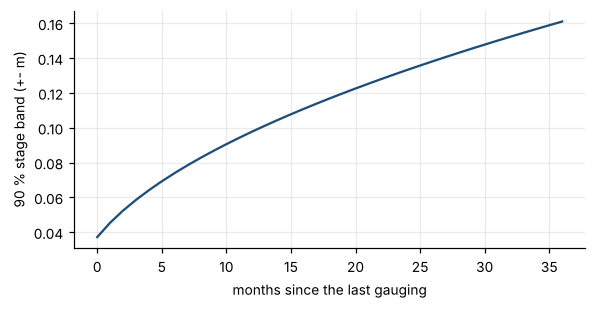

In [7]:
gr = D.band_growth(sd_last, F["q_m2_per_yr"], age)
for m, b in gr.items():
    print("after %2d more months without a gauging: +-%.3f m" % (m, b))
sd_g = SIGMA_ADCP * float(mk(float(mh(250.0))))
print("one ADCP gauging at 250 m3/s today would bring the band back to +-%.3f m" % D.band_after_gauging(sd_now, sd_g))
mm = np.arange(0, 37)
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.plot(mm, [D.Z90 * math.sqrt(sd_last ** 2 + F["q_m2_per_yr"] * m / 12) for m in mm], color="#1F4E79")
ax.set_xlabel("months since the last gauging"); ax.set_ylabel("90 % stage band (+- m)"); ax.grid(alpha=.25); plt.show()